In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

df = pd.read_csv("Iris.csv")
print(df.shape)
df.head()

(150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [3]:
# Id is just an identifier; Species is the original label (kept only for comparison)
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = StandardScaler().fit_transform(df[features])
y = df["Species"]

In [4]:
hdb = HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X)

C:\Users\andhi\AppData\Roaming\Python\Python314\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [5]:
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()

print(f"Number of clusters : {n_clusters}")
print(f"Noise points       : {n_noise} ({n_noise / len(labels) * 100:.2f}%)")

Number of clusters : 2
Noise points       : 2 (1.33%)


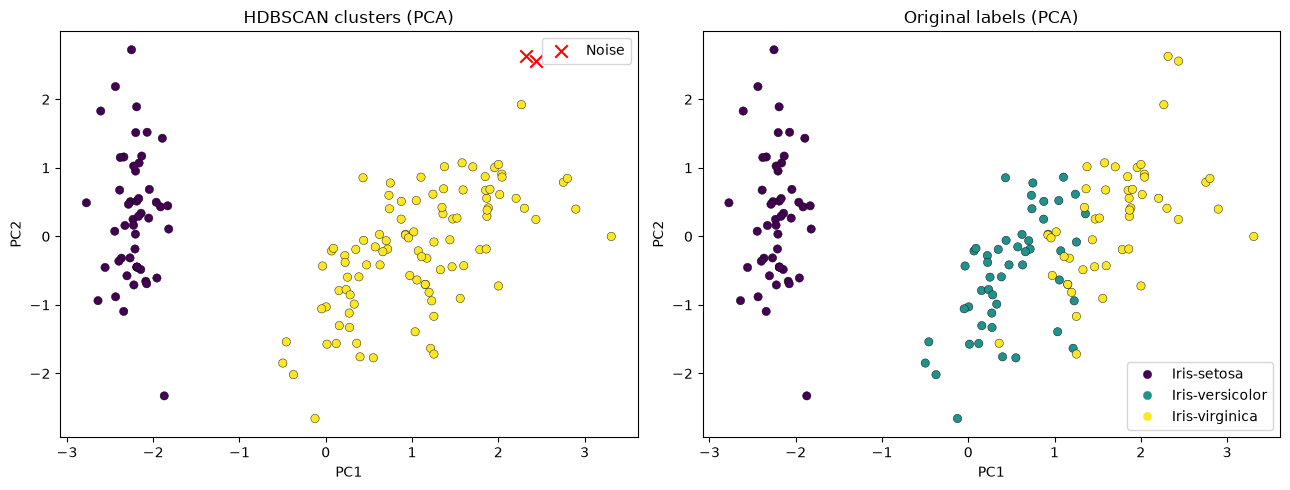

In [6]:
X_pca = PCA(n_components=2).fit_transform(X)
y_codes = y.astype("category").cat.codes

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Left: HDBSCAN result (noise marked with red x)
noise = labels == -1
ax[0].scatter(X_pca[~noise, 0], X_pca[~noise, 1], c=labels[~noise],
              cmap="viridis", edgecolor="k", linewidth=0.3)
ax[0].scatter(X_pca[noise, 0], X_pca[noise, 1], c="red", marker="x", s=80, label="Noise")
ax[0].set_title("HDBSCAN clusters (PCA)")
ax[0].legend()

# Right: original labels
sc = ax[1].scatter(X_pca[:, 0], X_pca[:, 1], c=y_codes, cmap="viridis",
                   edgecolor="k", linewidth=0.3)
ax[1].set_title("Original labels (PCA)")
ax[1].legend(sc.legend_elements()[0], y.astype("category").cat.categories)

for a in ax:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

In [7]:
ct = pd.crosstab(y, pd.Series(labels, name="HDBSCAN cluster"))
display(ct)

print("Adjusted Rand Index   :", round(adjusted_rand_score(y, labels), 3))
print("Normalized Mutual Info:", round(normalized_mutual_info_score(y, labels), 3))

HDBSCAN cluster,-1,0,1
Species,,,
Iris-setosa,0,50,0
Iris-versicolor,0,0,50
Iris-virginica,2,0,48


Adjusted Rand Index   : 0.564
Normalized Mutual Info: 0.717


## Analysis
HDBSCAN found 2 clusters and labelled 2 points (1.33%) as noise, while the dataset
has 3 original species. Iris-setosa is isolated perfectly in its own cluster.
Iris-versicolor and Iris-virginica are merged into one cluster, because they overlap
in feature space and there is no density gap between them. Both noise points are
Iris-virginica samples. The ARI (0.564) and NMI (0.717) show a moderate match: the
clustering agrees with the labels on the setosa vs. non-setosa split, but it does
not recover the three species. HDBSCAN finds density-based structure, which does
not always match the class labels.